# Minutiae extraction on the sample image

This notebook runs the extractor on `sample/sample_fingerprint.tif` and draws the result.

**What it needs**

- The installation of the [README](README.md): `uv sync`, `uv pip install -e .`, and the
  model weights in `models/` (`uv run python scripts/install_model.py`).
- A Jupyter kernel that uses that environment. Jupyter itself is not among the
  dependencies. This notebook was last executed from the repository directory with
  `uv run --with nbconvert jupyter nbconvert --to notebook --execute --inplace demo.ipynb`.
  Opening it in JupyterLab or VS Code was not tried for this version.
- The repository directory as working directory, because the paths below are relative.

**What to know**

- The stored outputs leave out the TensorFlow log lines and the Keras progress bars,
  which fill many screens when you run it yourself.
- It was run on a CPU only (4 cores), where it takes about two minutes. Running it on
  a GPU was never tried.
- The figures shown are for this one image. What the extractor finds on other prints is
  described in [docs/measurements.md](docs/measurements.md).

In [1]:
import os

# This notebook was only ever run on a CPU. The next line hides any GPU from TensorFlow,
# so that the notebook behaves the same on every machine. Remove it to try a GPU.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # fewer TensorFlow log lines

import cv2
import numpy as np
import tensorflow as tf
from matplotlib import pyplot as plt

from fingerflow.extractor import Extractor

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


## 1. Load the networks and run the extractor

The image has to be 8-bit, at about 500 ppi, with dark ridges on a light background (see
"Input images" in the README). The sample image meets this.

All four networks are loaded here: CoarseNet and FineNet find the minutiae, ClassifyNet
assigns a type to each, CoreNet detects the core.

In [2]:
extractor = Extractor('models/CoarseNet.h5', 'models/FineNet.h5',
                      'models/ClassifyNet_6_classes.h5', 'models/CoreNet.weights')

image = cv2.imread('sample/sample_fingerprint.tif')
print(f"Image: {image.shape[1]} x {image.shape[0]} px, {image.dtype}")

Loading FineNet weights from models/FineNet.h5


Loading ClassifyNet weights from models/ClassifyNet_6_classes.h5


nms iou: 0.413 score: 0.3


all weights read
Core net weights loaded from models/CoreNet.weights


Image: 296 x 560 px, uint8


In [3]:
result = extractor.extract_minutiae(image)

minutiae = result['minutiae']
print(f"{len(minutiae)} minutiae")
print(f"Columns: {list(minutiae.columns)}")
minutiae.head(10)

nms iou: 0.413 score: 0.3


51 minutiae
Columns: ['x', 'y', 'angle', 'score', 'class', 'direction_confidence']


,x,y,angle,score,class,direction_confidence
0,121.0,149.0,6.239221,0.998402,1.0,0.695495
1,169.0,382.0,1.752636,0.998863,0.0,0.665957
2,177.0,334.0,1.507795,0.998872,0.0,1.057563
3,217.0,310.0,1.286846,0.997997,1.0,0.920657
4,124.0,285.0,1.837194,0.995029,1.0,0.565101
5,187.0,404.0,1.779674,0.997406,1.0,0.914557
6,178.0,283.0,1.162923,0.996738,2.0,0.761481
7,149.0,372.0,2.791285,0.928443,5.0,0.418139
8,218.0,401.0,1.608013,0.995796,0.0,0.809385
9,94.0,178.0,2.788570,0.994878,0.0,0.774066


Each row is one minutia: `x` (column) and `y` (row) in px, `angle` in radians, `score`,
`class` (0 ending, 1 bifurcation, 2 fragment, 3 enclosure, 4 crossbar, 5 other) and
`direction_confidence` (0.25 or more means the direction is reliable).

The core is a second table, one row per detected box:

In [4]:
result['core']

,x1,y1,x2,y2,score,w,h
0,121,236,164,374,0.966214,43,138


## 2. Draw the minutiae

Red dots are the minutiae, blue arrows their direction `(cos(angle), sin(angle))`, and
the green box is the detected core.

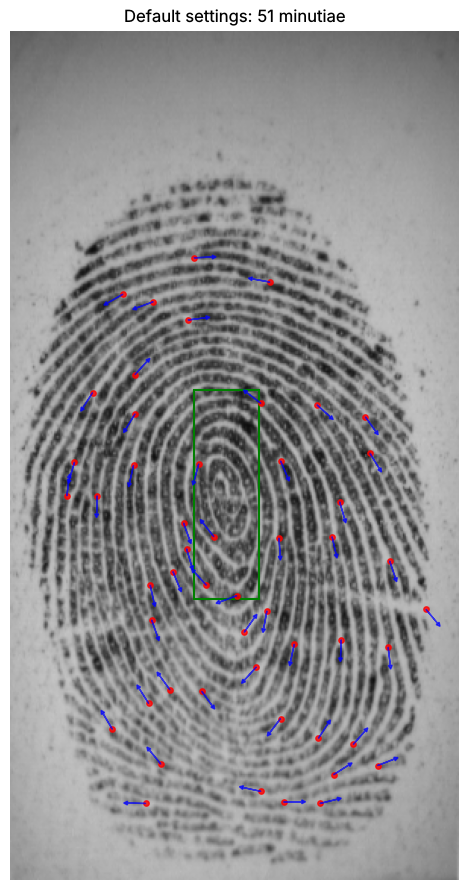

In [5]:
def draw_minutiae(axis, image, minutiae, title):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    for _, minutia in minutiae.iterrows():
        x, y, angle = minutia['x'], minutia['y'], minutia['angle']
        axis.arrow(x, y, 12 * np.cos(angle), 12 * np.sin(angle), head_width=2.5,
                   head_length=2.5, fc='blue', ec='blue', alpha=0.7, linewidth=1, zorder=4)
    axis.scatter(minutiae['x'], minutiae['y'], c='red', s=15, zorder=3, alpha=0.8)
    axis.set_title(title)
    axis.axis('off')


figure, axis = plt.subplots(figsize=(5, 9))
draw_minutiae(axis, image, minutiae, f'Default settings: {len(minutiae)} minutiae')

cores = result['core']
if cores is not None:
    for _, core in cores.iterrows():
        axis.add_patch(plt.Rectangle((core['x1'], core['y1']), core['w'], core['h'],
                                     fill=False, edgecolor='green', linewidth=1.5))

plt.tight_layout()
plt.show()

## 3. The settings for DeepPrint training data

DeepPrint needs only position and direction, so ClassifyNet and CoreNet can be left out
(`None` instead of a path). That is faster and needs less memory; the `class` column is
then `NaN` and the core result is `None`. Position, angle, score and direction confidence
are the same with and without the two networks.

The extractor below also switches on `crop_to_print` and `reweight_score`, the two
options that find more minutiae ([docs/usage.md](docs/usage.md#finding-more-minutiae)).
With `reweight_score` the `score` column has a different meaning than above.

The first extractor is deleted first, so that the networks are not held in memory twice.

In [6]:
del extractor

more_minutiae = Extractor('models/CoarseNet.h5', 'models/FineNet.h5', None, None,
                          crop_to_print=True, reweight_score=True)
options_result = more_minutiae.extract_minutiae(image)
options_minutiae = options_result['minutiae']

for name, table in (('default (section 1)', minutiae),
                    ('crop_to_print + reweight_score', options_minutiae)):
    clear = (table['direction_confidence'] >= 0.25).sum()
    print(f"{name}: {len(table)} minutiae, {clear} with direction_confidence >= 0.25, "
          f"lowest score {table['score'].min():.3f}")

print(f"class is NaN for every row: {options_minutiae['class'].isna().all()}")
print(f"core: {options_result['core']}")

Loading FineNet weights from models/FineNet.h5


default (section 1): 51 minutiae, 50 with direction_confidence >= 0.25, lowest score 0.453
crop_to_print + reweight_score: 60 minutiae, 56 with direction_confidence >= 0.25, lowest score 0.550
class is NaN for every row: True
core: None


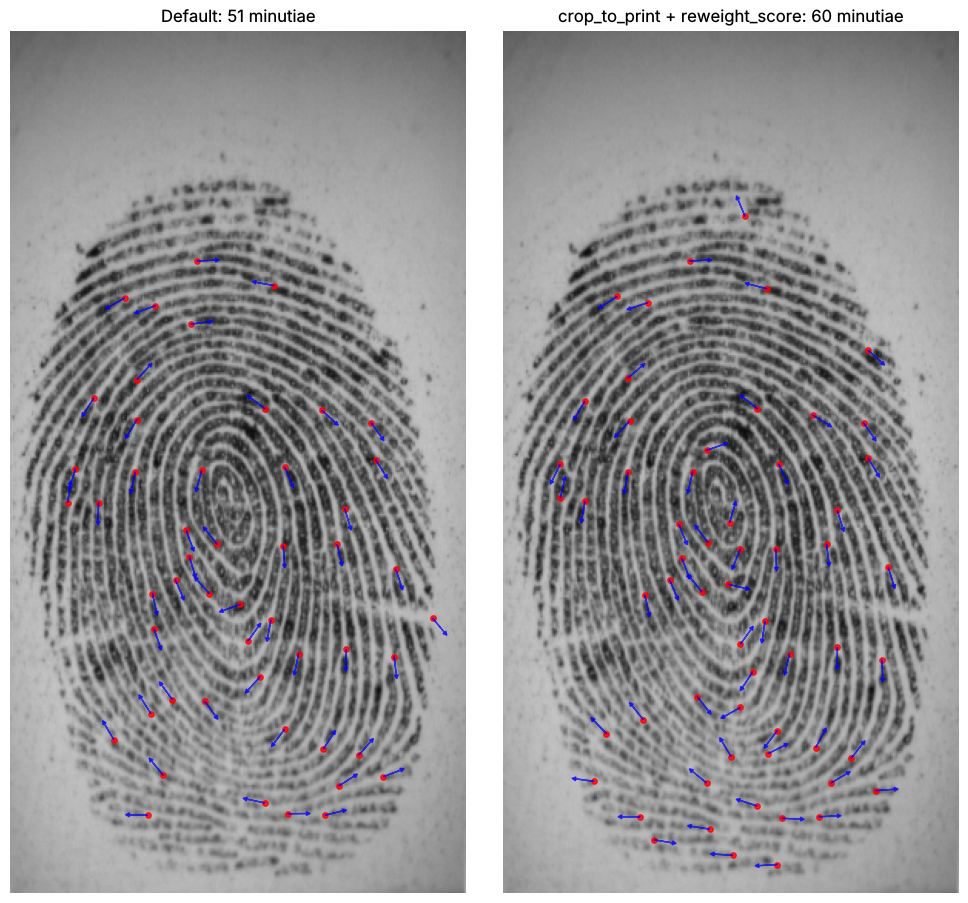

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(10, 9))
draw_minutiae(axes[0], image, minutiae, f"Default: {len(minutiae)} minutiae")
draw_minutiae(axes[1], image, options_minutiae,
              f"crop_to_print + reweight_score: {len(options_minutiae)} minutiae")
plt.tight_layout()
plt.show()

Looking at such a pair of pictures for a sample of your own images, from each sensor
type, is the check that [docs/usage.md](docs/usage.md#choosing) asks for before a large
run. Whether a detection is a real minutia cannot be read off this notebook: this image
has no minutiae marked by an examiner.

## 4. Image patches around the minutiae (illustration)

The networks FineNet and ClassifyNet look at a small image patch around each minutia.
The next cell shows such patches (64 x 64 px here) for the first twelve minutiae. It is
an illustration only; the package has no function that exports patches, and nothing is
written to disk.

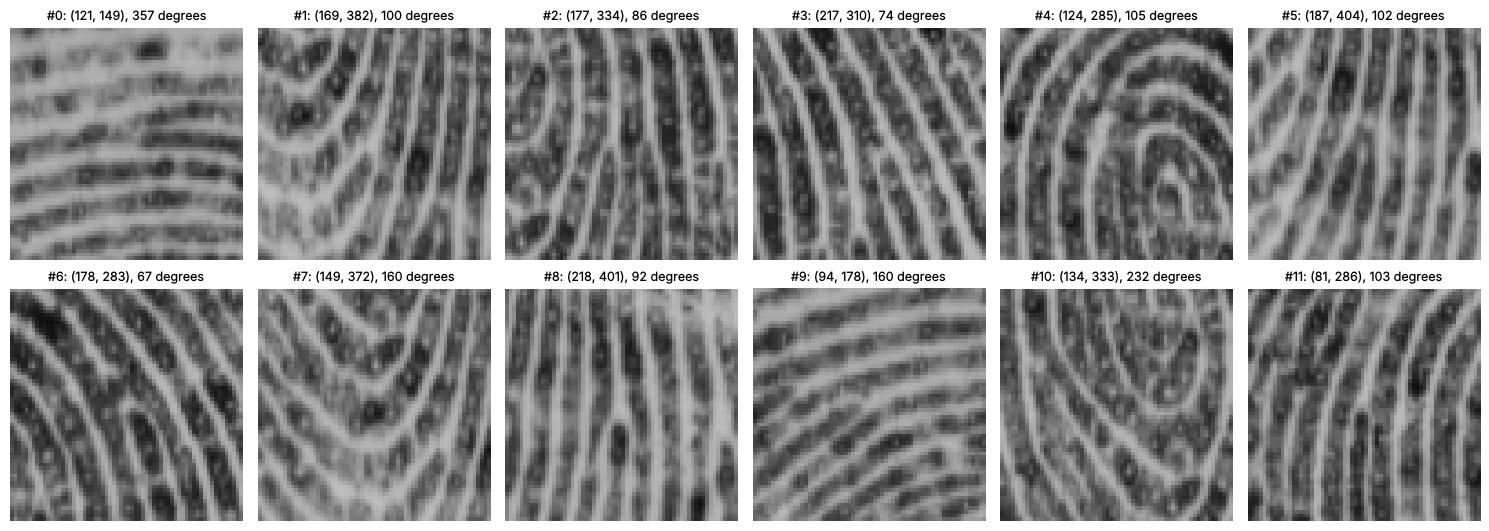

In [8]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
half = 32
padded = np.pad(gray, half, mode='constant', constant_values=255)

shown = minutiae.head(12)
figure, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for axis in axes.flatten():
    axis.axis('off')
for axis, (index, minutia) in zip(axes.flatten(), shown.iterrows()):
    x, y = int(minutia['x']), int(minutia['y'])
    axis.imshow(padded[y:y + 2 * half, x:x + 2 * half], cmap='gray', vmin=0, vmax=255)
    axis.set_title(f"#{index}: ({x}, {y}), {np.degrees(minutia['angle']):.0f} degrees",
                   fontsize=9)
plt.tight_layout()
plt.show()

## A note on the earlier version of this notebook

An earlier version removed every minutia whose own pixel was light after an Otsu
threshold (a method that splits the gray values of an image into dark and light) and
called the removed ones "spurious". That filter is not part of the package and was never
compared with minutiae marked by an examiner. On this image it discarded 29 of the 51
minutiae. It was removed from the notebook. Do not apply such a filter to minutiae that
are meant as training data.